# 03 - Image Preprocessing and PyTorch Dataset Pipeline
### UROP: Improving Cross-Dataset Generalization and Severe-Stage Detection in ROP
This notebook demonstrates and validates the preprocessing pipeline:
1. Retinal field detection and black background border cropping (`threshold > 15`).
2. Aspect-ratio preserving square padding.
3. High-quality Lanczos resizing to standardized input resolution (224x224).
4. Safe, clinically motivated training augmentations (rotations, flips, color jitter, mild blur).
5. Deterministic validation/test transforms without augmentation.
6. Verification of PyTorch `ROPDataset` and `DataLoader` batches.


In [1]:
import os, sys
if "COLAB_GPU" in os.environ or os.path.exists("/content"):
    sys.path.append("/content/drive/MyDrive/ROP_UROP")
    sys.path.append("/content/ROP_UROP")
else:
    sys.path.append(r"d:/UROP")

import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from src.preprocessing import preprocess_fundus_image, get_transforms
from src.dataset import ROPDataset, build_dataloaders


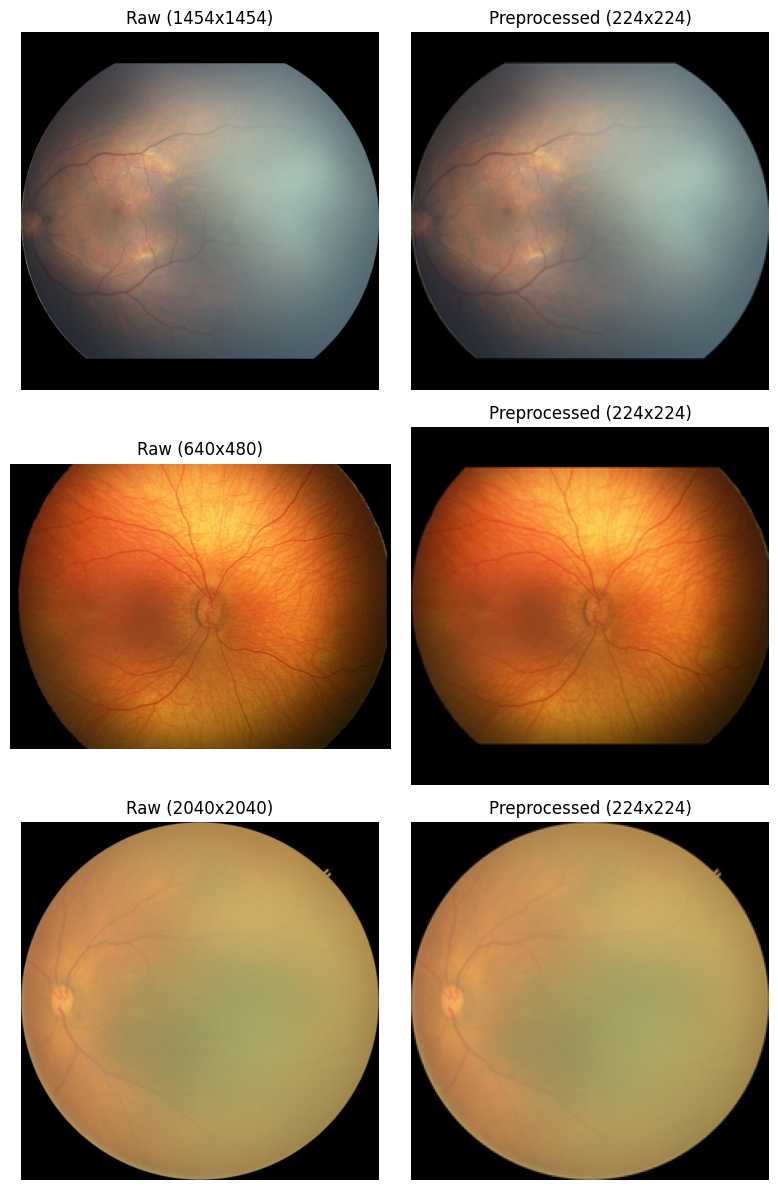

In [2]:
# Load sample Task A manifest and visualize preprocessing on sample images
taskA_path = r"d:/UROP\manifests\taskA_manifest.csv" if os.path.exists(r"d:/UROP") else "manifests/taskA_manifest.csv"
df = pd.read_csv(taskA_path)

samples = [
    df[df["dataset_source"] == "ROPVL"].iloc[0]["image_path"],
    df[df["dataset_source"] == "OSTRAVA"].iloc[0]["image_path"],
    df[df["dataset_source"] == "HVDROPDB"].iloc[0]["image_path"]
]

fig, axes = plt.subplots(len(samples), 2, figsize=(8, 4 * len(samples)))
for idx, path in enumerate(samples):
    raw = Image.open(path).convert("RGB")
    prep = preprocess_fundus_image(raw, target_size=224)
    axes[idx, 0].imshow(raw)
    axes[idx, 0].set_title(f"Raw ({raw.size[0]}x{raw.size[1]})")
    axes[idx, 0].axis("off")
    axes[idx, 1].imshow(prep)
    axes[idx, 1].set_title(f"Preprocessed (224x224)")
    axes[idx, 1].axis("off")

plt.tight_layout()
plt.show()


In [3]:
# Verify DataLoader batch generation
train_loader, val_loader = build_dataloaders(df, val_fold=0, batch_size=8, task="binary")
images, labels, meta = next(iter(train_loader))
print("Batch images shape:", images.shape)
print("Batch labels shape:", labels.shape)
print("Labels in batch:", labels.tolist())
print("Patient IDs in batch:", meta["patient_uid"])


Batch images shape: torch.Size([8, 3, 224, 224])
Batch labels shape: torch.Size([8])
Labels in batch: [0, 0, 0, 0, 1, 0, 0, 0]
Patient IDs in batch: ['OST_181', 'ROPVL_1007', 'OST_107', 'OST_070', 'ROPVL_508', 'OST_104', 'OST_057', 'OST_063']
